In [1]:
MODEL_CODE = "nb"
MODEL_NAME = "Naive Bayes"

# 05: Naive Bayes Modeli (Kişi 1)

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini · **Model ailesi:** olasılıksal / lineer

**Naive Bayes** Bayes teoremiyle her sınıfın olasılığını hesaplar ve olasılığı yüksek olan sınıfı seçer:

$$P(\text{inme} \mid x_1, \dots, x_n) \propto P(\text{inme}) \cdot P(x_1 \mid \text{inme}) \cdot P(x_2 \mid \text{inme}) \cdots P(x_n \mid \text{inme})$$

- **"Naive" (saf) varsayım:** Sınıf bilindiğinde özelliklerin **birbirinden bağımsız** olduğu varsayılır. Bu sayede her özelliğin olasılığı ayrı ayrı hesaplanıp çarpılabilir.
- **Gaussian Naive Bayes:** Sürekli özelliklerin her sınıf içinde **normal (Gauss) dağılıma** uyduğu varsayılır. Model her sınıf ve özellik için yalnızca bir ortalama ve bir varyans öğrenir.
- **Neden seçildi:** Çok hızlı, az parametreli ve küçük veride kararlı. Olasılıksal bir model olduğu için Logistic Regression ile aynı ailede, basit bir karşılaştırma noktası (baseline) sağlar.
- **Zayıf yanı:** Bağımsızlık varsayımı bu veride açıkça bozuluyor: `SYSBP`, `DIABP`, `pulse_pressure`, `mean_arterial_pressure` hepsi tansiyondan geliyor. Model aynı bilgiyi birden fazla kez sayar ve olasılıkları aşırı uçlara (0'a veya 1'e) iter.

**Bu notebook'ta yapılanlar:** dengeleme yöntemi karşılaştırması · hiperparametre araması · feature engineering etkisi (bağımsızlık varsayımı) · CV değerlendirmesi ve eşik seçimi · öğrenme eğrisi · test seti · XAI

## 1. Kurulum

In [2]:
# shap and lime are not preinstalled on Colab
try:
    import lime
    import shap
except ImportError:
    %pip install -q shap lime

In [3]:
import sys
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

# Çıktı klasörleri: repo kökünde models/ ve figures/ (Colab'da çalışma klasöründe)
ROOT = SRC_DIR.resolve().parent if SRC_DIR.name == "src" else Path(".")
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "figures";   FIG_DIR.mkdir(exist_ok=True)

import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB

from config import MAIN_METRIC, RANDOM_STATE, TARGET_RECALL
from preprocessing import build_pipeline, load_data
from metrics import (SCORING, cv_evaluate, learning_curve_analysis, shared_cv, test_evaluate,
                     threshold_analysis)
from explain import explain

warnings.filterwarnings("ignore")

## 2. Veri

`train.csv` / `test.csv`. Ön işleme (feature engineering, encoding, ölçekleme, SMOTE) `build_pipeline()` içinde yapılır; test seti en sona kadar kullanılmaz.

In [4]:
X_train, X_test, y_train, y_test = load_data()
print("Eğitim:", X_train.shape, f"| inme: {y_train.sum()} kişi ({y_train.mean():.2%})")
print("Test:  ", X_test.shape, f"| inme: {y_test.sum()} kişi ({y_test.mean():.2%})")

Eğitim: (3521, 17) | inme: 306 kişi (8.69%)
Test:   (881, 17) | inme: 77 kişi (8.74%)


## 3. Dengeleme yöntemi

`GaussianNB`'de `class_weight` parametresi yoktur. Bunun yerine Naive Bayes'e özgü üçüncü bir seçenek vardır: **önsel olasılıklar (priors)**. Model normalde inme olasılığına verinin kendisinden başlar (P(inme) ≈ 0.087). `priors=[0.5, 0.5]` verilirse model "iki sınıf eşit olasılıklı" diye başlar; bu, sınıf ağırlığının Naive Bayes'teki karşılığıdır.

| Seçenek | Nasıl |
|---|---|
| `none` | Dengeleme yok, önsel olasılık veriden (≈ 0.087) |
| `priors` | `GaussianNB(priors=[0.5, 0.5])`, `balancing="none"` |
| `smote` | Eğitim katlarına sentetik inme örnekleri |

Bu deneyler `results.csv`'ye yazılmaz (`save=False`).

In [5]:
options = {
    "none": build_pipeline(GaussianNB(), balancing="none"),
    "priors": build_pipeline(GaussianNB(priors=[0.5, 0.5]), balancing="none"),
    "smote": build_pipeline(GaussianNB(), balancing="smote"),
}
rows = {}
for name, pipe in options.items():
    res = cv_evaluate(pipe, X_train, y_train, model_name=f"{MODEL_NAME} ({name})", save=False, verbose=False)
    rows[name] = res["summary"]["cv_mean"]
balancing_table = pd.DataFrame(rows).T
balancing_table.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
none,0.405,0.175,0.244,0.818,0.686,0.169,0.782
priors,0.533,0.155,0.240,0.724,0.686,0.168,0.707
smote,0.644,0.137,0.225,0.614,0.661,0.188,0.617


**Okuma:**
- Eşikten bağımsız metrikler (ROC-AUC, PR-AUC) "none" ve "priors" seçeneklerinde **aynıdır** (fark yuvarlama düzeyinde). Önsel olasılığı değiştirmek her kişinin skorunu aynı yönde kaydırır, kişilerin risk **sıralamasını** değiştirmez. Değişen yalnızca eşik 0.5'teki kararlardır (recall artar, precision düşer). Eşik zaten Bölüm 7'de ayrıca seçileceği için "priors" seçeneği "none"dan farklı bir model üretmez; aramada yalnızca "none" ve "smote" denenir.
- SMOTE ise modelin öğrendiği ortalama ve varyansları değiştirir (sentetik örnekler inme sınıfının dağılımını yeniden şekillendirir), bu yüzden sıralama da değişebilir.
- Karar eşiği Bölüm 7'de ayrıca seçileceği için, seçimde eşikten bağımsız olan PR-AUC esas alınır.

## 4. Hiperparametre araması

GaussianNB'nin tek hiperparametresi `var_smoothing`'dir: her özelliğin varyansına, en büyük varyansın bu oranı kadar küçük bir değer eklenir. Amaç, varyansı çok küçük olan bir özellik yüzünden olasılıkların aşırı uçlara gitmesini engellemektir. Büyük değer = daha "yumuşak" olasılıklar = daha güçlü düzenlileştirme.

| Parametre | Değerler |
|---|---|
| `var_smoothing` | 1e-9 (varsayılan) ile 1000 arası, logaritmik 13 değer |
| dengeleme | `none`, `smote` |

Ortak katlar (`shared_cv()`) ve ortak metrikler (`SCORING`) kullanılır; en iyi model `MAIN_METRIC` (PR-AUC) ile seçilir.

In [6]:
def search_table(search, params):
    """Hiperparametre denemeleri: eğitim ve CV skoru, aradaki fark (overfitting göstergesi)."""
    r = pd.DataFrame(search.cv_results_)
    t = r[[f"param_{p}" for p in params]].copy()
    t.columns = [p.replace("model__", "") for p in params]
    for m in [MAIN_METRIC, "recall", "roc_auc"]:
        t[f"{m}_cv"] = r[f"mean_test_{m}"]
    t[f"{MAIN_METRIC}_train"] = r[f"mean_train_{MAIN_METRIC}"]
    t["fark (train - cv)"] = t[f"{MAIN_METRIC}_train"] - t[f"{MAIN_METRIC}_cv"]
    return t.sort_values(f"{MAIN_METRIC}_cv", ascending=False).round(4)

In [7]:
params = {"model__var_smoothing": np.logspace(-9, 3, 13)}
start = time.time()
searches = {}
for balancing in ["none", "smote"]:
    s = GridSearchCV(build_pipeline(GaussianNB(), balancing=balancing), params, cv=shared_cv(),
                     scoring=SCORING, refit=MAIN_METRIC, n_jobs=-1, return_train_score=True)
    s.fit(X_train, y_train)
    searches[balancing] = s
    print(f"{balancing:6s} | en iyi CV {MAIN_METRIC} = {s.best_score_:.4f} | {s.best_params_}")

best_balancing = max(searches, key=lambda b: searches[b].best_score_)
search = searches[best_balancing]
best = search.best_estimator_

print(f"\nSüre: {time.time() - start:.0f} sn")
print(f"Seçilen: balancing = {best_balancing}, {search.best_params_}")
search_table(search, list(params))

none   | en iyi CV pr_auc = 0.1967 | {'model__var_smoothing': 10.0}


smote  | en iyi CV pr_auc = 0.1956 | {'model__var_smoothing': 1000.0}

Süre: 4 sn
Seçilen: balancing = none, {'model__var_smoothing': 10.0}


,var_smoothing,pr_auc_cv,recall_cv,roc_auc_cv,pr_auc_train,fark (train - cv)
10,10.0000,0.1967,0.0000,0.6996,0.1914,-0.0053
11,100.0000,0.1948,0.0000,0.6991,0.1916,-0.0032
12,1000.0000,0.1948,0.0000,0.6990,0.1915,-0.0033
9,1.0000,0.1863,0.1796,0.7017,0.1854,-0.0009
8,0.1000,0.1823,0.3593,0.6987,0.1817,-0.0006
7,0.0100,0.1742,0.4116,0.6898,0.1747,0.0005
6,0.0010,0.1702,0.4084,0.6867,0.1706,0.0003
4,0.0000,0.1692,0.4051,0.6864,0.1698,0.0007
0,0.0000,0.1691,0.4051,0.6864,0.1698,0.0007
1,0.0000,0.1691,0.4051,0.6864,0.1698,0.0007


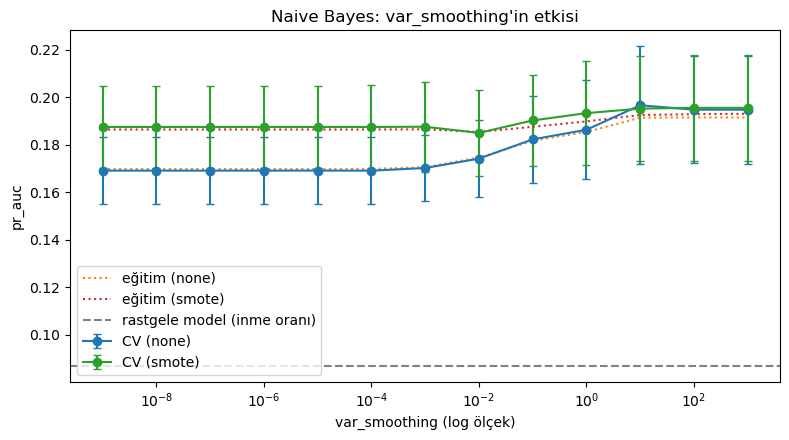

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for balancing, s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    x = r["param_model__var_smoothing"].astype(float)
    ax.errorbar(x, r[f"mean_test_{MAIN_METRIC}"], yerr=r[f"std_test_{MAIN_METRIC}"], fmt="o-",
                capsize=3, label=f"CV ({balancing})")
    ax.plot(x, r[f"mean_train_{MAIN_METRIC}"], ":", label=f"eğitim ({balancing})")
ax.axhline(y_train.mean(), color="gray", linestyle="--", label="rastgele model (inme oranı)")
ax.set_xscale("log")
ax.set_xlabel("var_smoothing (log ölçek)")
ax.set_ylabel(MAIN_METRIC)
ax.set_title(f"{MODEL_NAME}: var_smoothing'in etkisi")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_var_smoothing.png", dpi=200)
plt.show()

**Okuma:**
- 1e-9 ile 1e-3 arasında skor değişmiyor: varsayılan değer pratikte bir şey yapmıyor.
- `var_smoothing` büyüdükçe PR-AUC **artıyor** ve yaklaşık 10'dan sonra düzleşiyor. Eklenen sabit bütün varyansları büyütüyor; özellikle varyansı küçük olan 0/1 sütunların ve one-hot kategorilerin ağırlığı azalıyor ve model, bağımsızlık varsayımı yüzünden aynı bilgiyi tekrar tekrar sayarken oluşan **aşırı güveni** kaybediyor.
- **Bedeli:** Varyanslar bu kadar büyüyünce iki sınıfın olasılık dağılımları birbirine çok yaklaşır ve modelin ürettiği olasılıklar önsel olasılığın (≈ 0.087) etrafına **sıkışır** (Bölüm 7'deki grafik). Sıralama (kimin daha riskli olduğu) korunur, PR-AUC bu yüzden iyidir; ama eşik 0.5'te model hiç kimseye "inme var" demez (aşağıdaki tabloda recall = 0). Bu, eşiğin ayrıca seçilmesini zorunlu kılar.
- Eğitim ve CV skorları neredeyse aynı: Naive Bayes her sınıf ve özellik için yalnızca bir ortalama ve bir varyans öğrendiği için ezberleyecek kapasitesi yok.
- "none" (0.197) ile "smote" (0.196) arasındaki fark, katlar arası standart sapmanın (≈ 0.02) çok altında: gerçek bir fark yok. Seçim kuralı gereği PR-AUC'si en yüksek olan (none, var_smoothing = 10) alındı.

## 5. Feature engineering'in etkisi: bağımsızlık varsayımı

Ortak pipeline 5 yeni özellik ekler (17 → 28 sütun). Bunların çoğu tansiyondan türetilmiştir (`pulse_pressure`, `mean_arterial_pressure`, `bp_stage`) ve `comorbidity_count` da `DIABETES`, `PREVHYP`, `PREVCHD` sütunlarının toplamıdır. Naive Bayes özelliklerin bağımsız olduğunu varsaydığı için bu tekrar eden bilgiyi **birden fazla kez sayar**. Feature engineering açık ve kapalı karşılaştırılır (bu deneyler `results.csv`'ye yazılmaz).

In [9]:
best_nb = best.named_steps["model"]
balancing_arg = best_balancing
rows = {}
for fe in [True, False]:
    res = cv_evaluate(build_pipeline(best_nb, balancing=balancing_arg, feature_engineering=fe),
                      X_train, y_train, model_name=f"{MODEL_NAME} (FE={fe})", save=False, verbose=False)
    rows["FE açık" if fe else "FE kapalı"] = res["summary"]["cv_mean"]
fe_table = pd.DataFrame(rows).T
fe_table.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
FE açık,0.0,0.0,0.0,1.0,0.700,0.197,0.913
FE kapalı,0.0,0.0,0.0,1.0,0.707,0.195,0.913


In [10]:
# Tansiyon sütunları arasındaki korelasyon: bağımsızlık varsayımı ne kadar bozuluyor?
X_fe = best.named_steps["fe"].transform(X_train)
bp_cols = ["SYSBP", "DIABP", "pulse_pressure", "mean_arterial_pressure"]
X_fe[bp_cols].corr().round(2)

,SYSBP,DIABP,pulse_pressure,mean_arterial_pressure
SYSBP,1.00,0.78,0.87,0.94
DIABP,0.78,1.00,0.37,0.95
pulse_pressure,0.87,0.37,1.00,0.65
mean_arterial_pressure,0.94,0.95,0.65,1.00


**Okuma:** Tansiyon sütunları birbiriyle çok yüksek korelasyonludur (`SYSBP` ile `mean_arterial_pressure` arasında 0.94, `DIABP` ile 0.95). Bağımsızlık varsayımı bu sütunlarda açıkça bozulur: model tansiyon bilgisini dört kez sayar. Buna rağmen feature engineering açık ve kapalı skorlar neredeyse aynıdır (PR-AUC 0.197 / 0.195). Bunun nedeni, seçilen büyük `var_smoothing` değerinin modelin aşırı güvenini zaten frenlemesidir. Final model, ekiple karşılaştırılabilir olsun diye ortak pipeline (FE açık) ile değerlendirilir.

(Eşik 0.5'teki recall/precision değerlerinin 0 olması Bölüm 4'te açıklanan olasılık sıkışmasından kaynaklanır; burada eşikten bağımsız ROC-AUC ve PR-AUC'ye bakılmalıdır.)

## 6. Final model: CV değerlendirmesi

Seçilen model ortak `cv_evaluate` ile değerlendirilir ve sonucu `results.csv`'ye **bir satır** olarak eklenir. Eğitim ve CV skorları arasındaki fark (`gap`) overfitting göstergesidir.

In [11]:
cv_result = cv_evaluate(best, X_train, y_train, model_name=MODEL_NAME,
                        note=f"GaussianNB, balancing={best_balancing}, var_smoothing={best_nb.var_smoothing:g}")

===== Naive Bayes: 5 katlı CV (eşik = 0.5) =====
Kat başına ortalama eğitim süresi: 0.01 sn

             train_mean  cv_mean  cv_std    gap
metric                                         
recall            0.000    0.000   0.000  0.000
precision         0.000    0.000   0.000  0.000
f1                0.000    0.000   0.000  0.000
specificity       1.000    1.000   0.000  0.000
roc_auc           0.704    0.700   0.023  0.004
pr_auc            0.191    0.197   0.028 -0.005
accuracy          0.913    0.913   0.001 -0.000

Sonuç 'results.csv' dosyasına eklendi.


## 7. Eşik seçimi

Seçilen modelde olasılıklar önsel olasılığın etrafına sıkıştığı için (çoğu kişi 0.04 ile 0.12 arasında) varsayılan eşik 0.5 bu modelde anlamsızdır: hiç kimse 0.5'i geçmez. Eşik, **test setine bakılmadan** CV tahminleri (OOF) üzerinde seçilir: hedef recall'u (%80) en az yanlış alarmla sağlayan eşik.

**Dikkat:** Olasılıklar dar bir aralıkta toplandığı için eşik çok hassastır. Tabloda eşik 0.05'ten 0.10'a çıkınca recall 0.96'dan 0.28'e düşüyor. Bu, modelin olasılıklarının **kalibre olmadığını** (gerçek risk yüzdesi olarak okunamayacağını) gösterir; yalnızca kişileri riske göre sıralamak için güvenilirdir.

===== Naive Bayes: Eşik analizi (toplam 306 inme, 3521 kişi) =====
 threshold  caught  missed  false_alarms  recall  precision  specificity  false_alarms_per_1000
      0.05     295      11          2892   0.964      0.093        0.100                821.358
      0.10      86     220           361   0.281      0.192        0.888                102.528
      0.15      13     293            35   0.042      0.271        0.989                  9.940
      0.20       3     303             3   0.010      0.500        0.999                  0.852
      0.25       2     304             2   0.007      0.500        0.999                  0.568
      0.30       1     305             0   0.003      1.000        1.000                  0.000
      0.35       0     306             0   0.000      0.000        1.000                  0.000
      0.40       0     306             0   0.000      0.000        1.000                  0.000
      0.45       0     306             0   0.000      0.000        1.

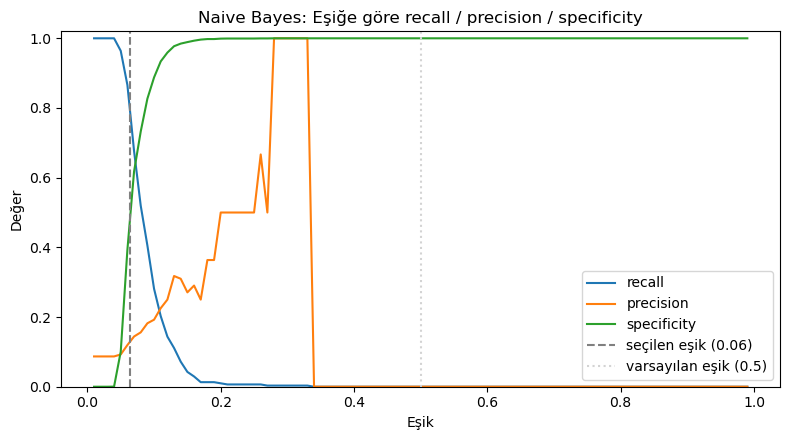

In [12]:
table, threshold = threshold_analysis(cv_result["y"], cv_result["oof_score"], model_name=MODEL_NAME)

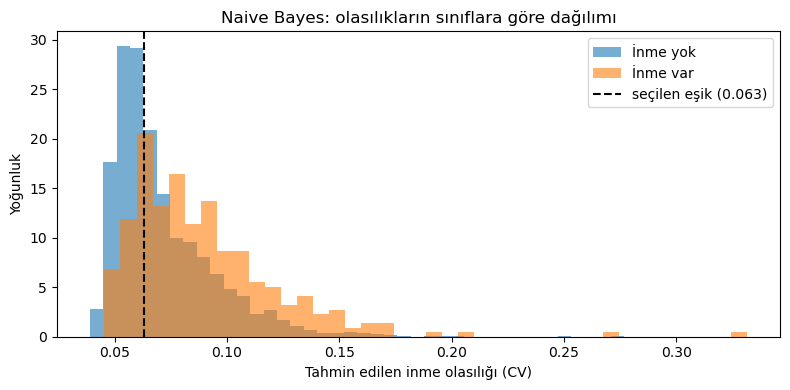

In [13]:
# Olasılıkların dağılımı: Naive Bayes skorları uçlarda mı toplanıyor?
fig, ax = plt.subplots(figsize=(8, 4))
for label, name in [(0, "İnme yok"), (1, "İnme var")]:
    ax.hist(cv_result["oof_score"][cv_result["y"] == label], bins=40, alpha=0.6, density=True, label=name)
ax.axvline(threshold, color="black", linestyle="--", label=f"seçilen eşik ({threshold:.3f})")
ax.set_xlabel("Tahmin edilen inme olasılığı (CV)")
ax.set_ylabel("Yoğunluk")
ax.set_title(f"{MODEL_NAME}: olasılıkların sınıflara göre dağılımı")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_score_distribution.png", dpi=200)
plt.show()

## 8. Overfitting kontrolü: öğrenme eğrisi

Eğitim verisi büyüdükçe eğitim ve CV skorları birbirine yaklaşıyorsa model genelleşiyor demektir. Büyük ve kapanmayan bir fark overfitting, ikisinin birlikte düşük kalması underfitting gösterir.

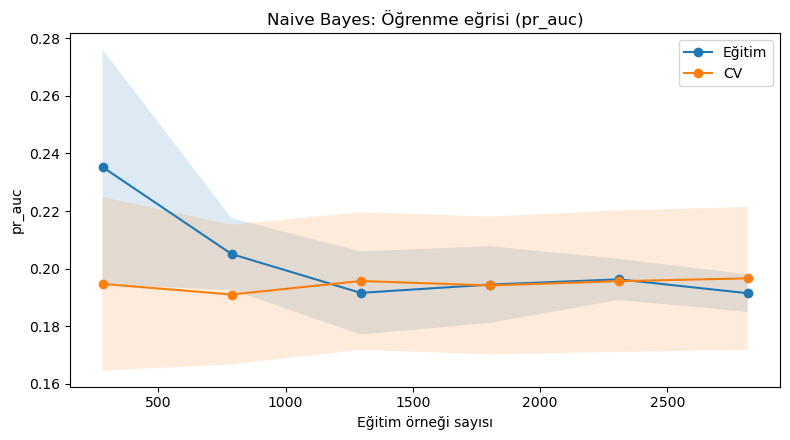

,train_size,train_mean,cv_mean,cv_std
0,281,0.235,0.195,0.030
1,788,0.205,0.191,0.024
2,1295,0.192,0.196,0.024
3,1802,0.194,0.194,0.024
4,2309,0.196,0.196,0.025
5,2816,0.191,0.197,0.025


In [14]:
lc = learning_curve_analysis(best, X_train, y_train, model_name=MODEL_NAME)
lc.round(3)

## 9. Test seti (yalnızca bir kez)

Final model tüm eğitim verisiyle yeniden eğitilir, seçilen eşikle test setinde değerlendirilir ve `models/` klasörüne kaydedilir.

===== Naive Bayes: Test seti (eşik = 0.063) =====
63/77 inme yakalandı, 14 inme kaçırıldı, 399 yanlış alarm (881 kişi).

             cv_same_threshold   test  cv_minus_test
recall                   0.801  0.818         -0.018
precision                0.129  0.136         -0.008
f1                       0.222  0.234         -0.012
specificity              0.485  0.504         -0.019
roc_auc                  0.698  0.754         -0.057
pr_auc                   0.185  0.235         -0.050
accuracy                 0.512  0.531         -0.019


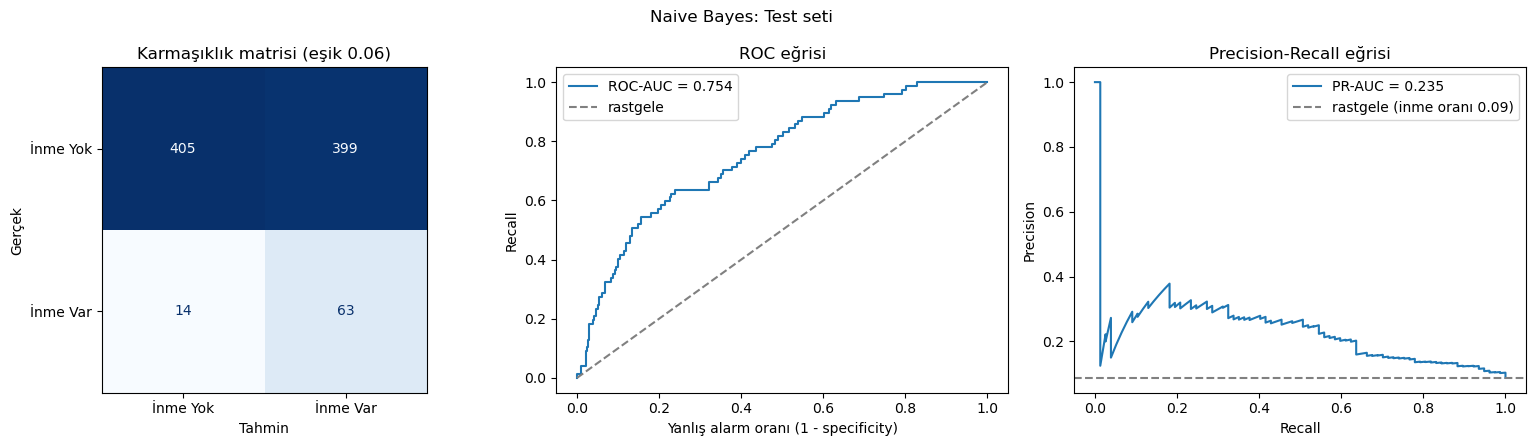

Model kaydedildi: models/nb.joblib


In [15]:
best.fit(X_train, y_train)
test_result = test_evaluate(best, X_test, y_test, threshold=threshold,
                            model_name=MODEL_NAME, cv_result=cv_result)

joblib.dump(best, MODEL_DIR / f"{MODEL_CODE}.joblib")
print(f"Model kaydedildi: models/{MODEL_CODE}.joblib")

## 10. Modelin öğrendikleri: sınıf ortalamaları

GaussianNB her özellik için iki sınıfın ortalamasını ve varyansını öğrenir. Özellikler standartlaştırıldığı için ortalamalar standart sapma cinsindendir: iki sınıfın ortalaması arasındaki fark ne kadar büyükse, o özellik iki sınıfı o kadar iyi ayırır. Bu, modelin kendi içinden okunabilen açıklamasıdır.

In [16]:
nb = best.named_steps["model"]
feature_names = best.named_steps["encode"].get_feature_names_out()
means = pd.DataFrame(nb.theta_.T, index=feature_names, columns=["ortalama (inme yok)", "ortalama (inme var)"])
means["fark"] = means["ortalama (inme var)"] - means["ortalama (inme yok)"]
means = means.reindex(means["fark"].abs().sort_values(ascending=False).index)
means.head(12).round(3)

,ortalama (inme yok),ortalama (inme var),fark
AGE,-0.059,0.620,0.679
SYSBP,-0.057,0.599,0.656
mean_arterial_pressure,-0.056,0.591,0.647
comorbidity_count,-0.051,0.535,0.586
DIABP,-0.049,0.520,0.569
pulse_pressure,-0.046,0.481,0.527
PREVHYP,0.302,0.575,0.273
bp_stage_stage2,0.345,0.601,0.257
BMI,-0.022,0.229,0.250
educ,0.016,-0.164,-0.180


## 11. XAI: modelin açıklanması

Naive Bayes ağaç ya da lineer model olmadığı için ortak `explain()` fonksiyonu **KernelExplainer** kullanır. Bu yöntem modelin içine bakmaz, özellikleri değiştirerek tahminin nasıl değiştiğini dener; bu yüzden yavaştır ve sonucu yaklaşıktır. Süreyi kısaltmak için test setinden 100 hasta ve eğitim verisinin 20 küme merkezi kullanılır. Naive Bayes'in tahmini çok hızlı olduğu için bu adım yine de kısa sürer. XAI fonksiyonuna aramanın kendisi değil, `search.best_estimator_` (`best`) verilir.

**Grafik okuma:** Bar grafiğinde çubuk uzunluğu önemi gösterir. Özet grafiğinde kırmızı = özelliğin değeri yüksek, mavi = düşük; nokta sağdaysa inme riskini artırıyor. LIME'da yeşil çubuklar "inme var" kararını destekleyen koşullardır.

===== Naive Bayes: XAI Analizi =====


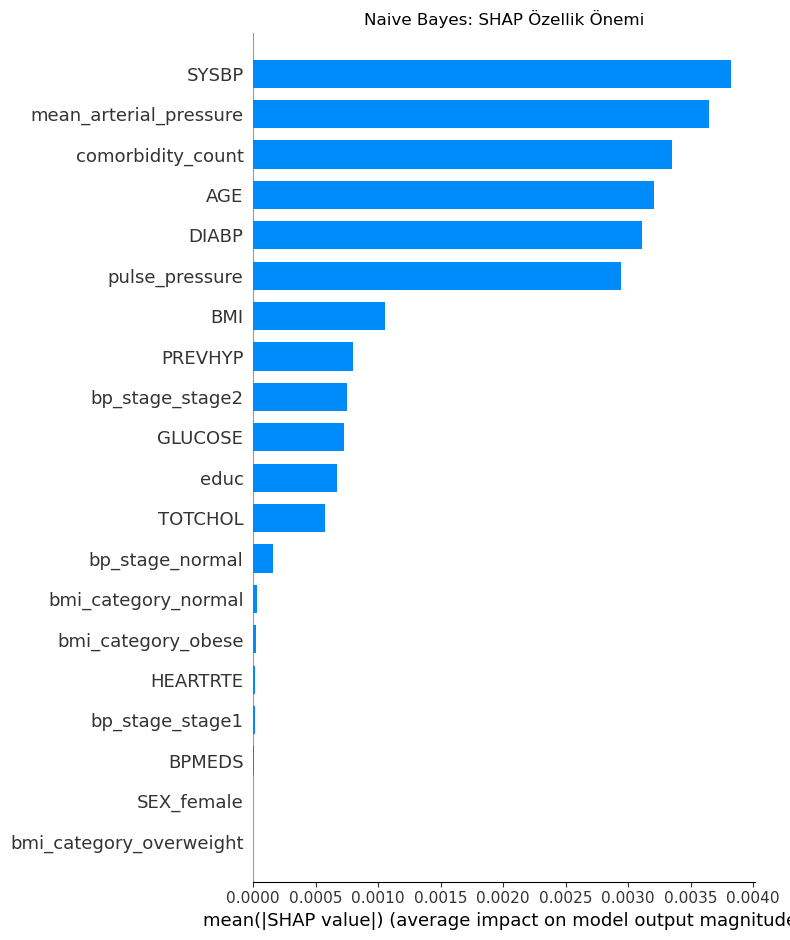

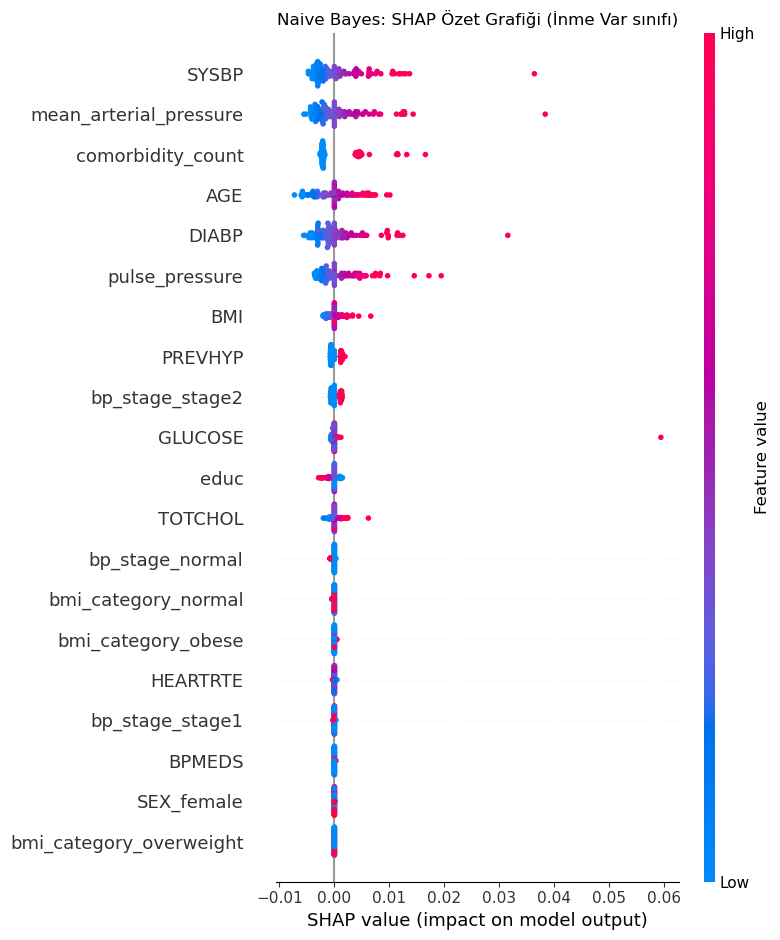


En önemli 5 özellik (SHAP):
               feature  mean_abs_shap
                 SYSBP       0.003821
mean_arterial_pressure       0.003643
     comorbidity_count       0.003352
                   AGE       0.003208
                 DIABP       0.003110

[Naive Bayes] Test hastası #789: İnme olasılığı = 23.72%


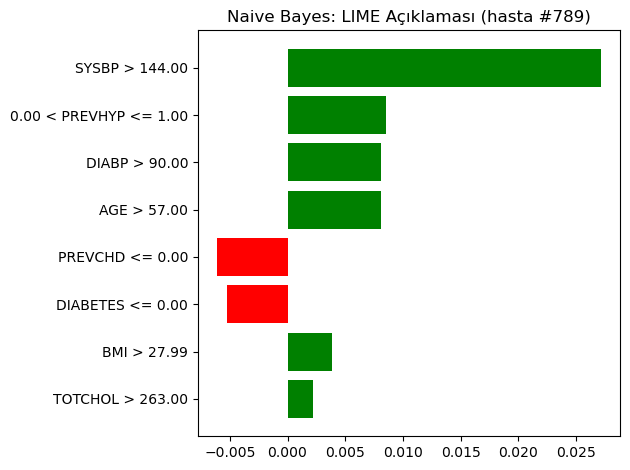


XAI süresi: 5 sn
Grafikler kaydedildi: ['nb_lime.png', 'nb_score_distribution.png', 'nb_shap_bar.png', 'nb_shap_summary.png', 'nb_var_smoothing.png']


In [17]:
# explain() grafikleri sırayla gösterir: SHAP bar, SHAP özet, LIME.
# Her grafik gösterilirken figures/ klasörüne de kaydedilir.
_names = iter([f"{MODEL_CODE}_shap_bar.png", f"{MODEL_CODE}_shap_summary.png", f"{MODEL_CODE}_lime.png"])
_show = plt.show
def _save_and_show(*args, **kwargs):
    name = next(_names, None)
    if name:
        plt.gcf().savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_and_show
try:
    start = time.time()
    xai = explain(best, X_train, X_test, model_name=MODEL_NAME, sample_size=100, background_size=20)
    print(f"\nXAI süresi: {time.time() - start:.0f} sn")
finally:
    plt.show = _show
print("Grafikler kaydedildi:", [p.name for p in sorted(FIG_DIR.glob(f"{MODEL_CODE}_*.png"))])

In [18]:
xai["shap_importance"].head(10)

,feature,mean_abs_shap
0,SYSBP,0.003821
1,mean_arterial_pressure,0.003643
2,comorbidity_count,0.003352
3,AGE,0.003208
4,DIABP,0.003110
5,pulse_pressure,0.002939
6,BMI,0.001052
7,PREVHYP,0.000801
8,bp_stage_stage2,0.000754
9,GLUCOSE,0.000729


## 12. Özet (rapor için)

- **Model:** Gaussian Naive Bayes, dengeleme yok, `var_smoothing = 10`. En iyi ayar 5 katlı CV'de PR-AUC'ye göre GridSearch ile seçildi (2 dengeleme × 13 `var_smoothing` değeri). SMOTE ile en iyi ayar neredeyse aynı skoru verdi (fark CV standart sapmasının altında). `class_weight` parametresi olmadığı için önsel olasılıklar (`priors=[0.5, 0.5]`) da denendi; risk sıralamasını değiştirmediği için ayrı bir model üretmedi.
- **CV sonucu:** PR-AUC 0.197 ± 0.028, ROC-AUC 0.700 ± 0.023. Rastgele bir modelin PR-AUC'si inme oranına (≈ 0.087) eşittir; model bunun yaklaşık 2,3 katı.
- **Overfitting yok:** eğitim ile CV arasındaki PR-AUC farkı ≈ 0, öğrenme eğrileri üst üste. Model az parametreli (sınıf başına ortalama + varyans).
- **Bağımsızlık varsayımı:** Tansiyondan türetilen dört sütun arasında korelasyon 0.94–0.95'e çıkıyor; varsayım açıkça bozuluyor. Model bunu güçlü `var_smoothing` ile telafi ediyor: skor artıyor ama olasılıklar önsel olasılığın etrafına sıkışıyor, eşik 0.5'te hiç "inme var" demiyor. Olasılıklar kalibre değil, yalnızca sıralama güvenilir.
- **Karar eşiği:** test setine bakılmadan, CV tahminlerinde recall ≥ %80 sağlayan en yüksek eşik olarak 0.063 seçildi. Olasılıklar dar aralıkta olduğu için eşik çok hassas.
- **Test seti (eşik 0.063):** 77 inmenin 63'ü yakalandı (recall 0.82), 14'ü kaçırıldı; karşılığında 881 kişide 399 yanlış alarm (precision 0.136). ROC-AUC 0.754, PR-AUC 0.235. Test sonuçları CV'ye yakın.
- **Açıklanabilirlik:** Sınıf ortalamaları ve SHAP aynı özellikleri öne çıkarıyor: **yaş**, **tansiyon** (SYSBP, ortalama arter basıncı, DIABP, nabız basıncı) ve **eşlik eden hastalık sayısı**. SHAP'ta tansiyon sütunları ayrı ayrı yüksek önem alıyor: bağımsızlık varsayımının "aynı bilgiyi birden fazla kez sayma" etkisi açıklamada da görülüyor. SHAP değerleri çok küçük (olasılık ölçeğinde ≈ 0.003), çünkü modelin olasılıkları dar bir aralıkta.
- **Logistic Regression ile karşılaştırma:** Aynı ailede olmalarına rağmen LR biraz daha iyi (PR-AUC 0.208'e karşı 0.197, fark standart sapmanın içinde) ve olasılıkları daha anlamlı. LR birbirine bağlı özelliklerin ağırlığını birlikte ayarlayabilirken Naive Bayes her özelliği ayrı değerlendiriyor.
- **Avantaj / dezavantaj:** Çok hızlı (kat başına 0,01 sn), az parametreli, overfitting riski yok, küçük veride kararlı. Ancak bağımsızlık varsayımı bu veride bozuk, olasılıkları kalibre değil ve özellikler arası etkileşimi öğrenemiyor.